# Multiple outputs

DJINN can predict several targets at once with one network per tree. Here the
inputs are the launch speed and angle of a projectile, and the two outputs are
how far it goes and how high it gets.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

from djinn import DJINN_Regressor

## Data

Without drag, a projectile launched at speed $v$ and angle $\theta$ travels a
range $R = v^2 \sin(2\theta) / g$ and reaches a height
$H = v^2 \sin^2(\theta) / (2g)$. A little noise is added to both.

In [2]:
rng = np.random.default_rng(0)
n = 2000
speed = rng.uniform(10, 50, n)  # m/s
angle = rng.uniform(10, 80, n)  # degrees
g = 9.81

theta = np.radians(angle)
distance = speed**2 * np.sin(2 * theta) / g
height = speed**2 * np.sin(theta) ** 2 / (2 * g)

X = np.column_stack([speed, angle])
Y = np.column_stack([distance, height])
Y += rng.normal(0, 0.02 * Y.std(axis=0), Y.shape)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)
X_train.shape, Y_train.shape

((1600, 2), (1600, 2))

## Fit

Nothing changes for multiple outputs: pass a 2-D `y` and the networks get one
output neuron per column. The random forest is fit on all the outputs together,
so each tree's splits are chosen for both targets.

In [3]:
%%time
model = DJINN_Regressor(
    n_trees=3,
    max_tree_depth=6,
    learning_rate=0.005,
    epochs=300,
    random_state=0,
)
model.fit(X_train, Y_train)

CPU times: user 4min 41s, sys: 24.2 s, total: 5min 5s
Wall time: 26.6 s


DJINN_Regressor(epochs=300, learning_rate=0.005, max_tree_depth=6, n_trees=3,
                random_state=0)

## Predict

`predict()` returns one column per output. `score()` averages R² over the
outputs, so the per-output numbers are worth checking too.

In [4]:
Y_pred = model.predict(X_test)
print(Y_pred.shape)
print(f"Mean R2: {model.score(X_test, Y_test):.3f}")
for i, name in enumerate(["distance (m)", "height (m)"]):
    r2 = r2_score(Y_test[:, i], Y_pred[:, i])
    mae = mean_absolute_error(Y_test[:, i], Y_pred[:, i])
    print(f"{name:<13} R2={r2:.3f}  MAE={mae:.2f}")

(400, 2)
Mean R2: 0.999
distance (m)  R2=0.999  MAE=1.51
height (m)    R2=0.999  MAE=0.65


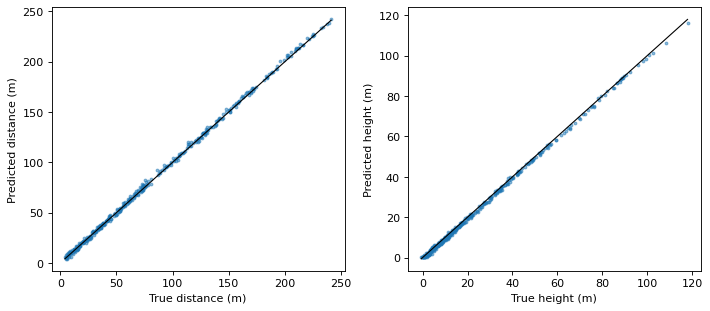

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(9, 4), dpi=80)
for ax, i, name in zip(axs, range(2), ["Distance (m)", "Height (m)"]):
    ax.scatter(Y_test[:, i], Y_pred[:, i], s=6, alpha=0.5)
    lims = [Y_test[:, i].min(), Y_test[:, i].max()]
    ax.plot(lims, lims, color="k", lw=1)
    ax.set_xlabel(f"True {name.lower()}")
    ax.set_ylabel(f"Predicted {name.lower()}")
fig.tight_layout()
plt.show()

A 1-D `y` gives 1-D predictions, the same as other scikit-learn regressors. A
target with one column, `y.reshape(-1, 1)`, keeps the column.

In [6]:
single = DJINN_Regressor(
    n_trees=1, max_tree_depth=6, learning_rate=0.005, epochs=50, random_state=0
)
print(single.fit(X_train, Y_train[:, 0]).predict(X_test).shape)
print(single.fit(X_train, Y_train[:, :1]).predict(X_test).shape)

(400,)


(400, 1)
